## Workshop -1 Adding Sunglasses to Your Passport Photo Using OpenCV


## Name : YOGESH.S

## Reg No : 212224230311

In [1]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

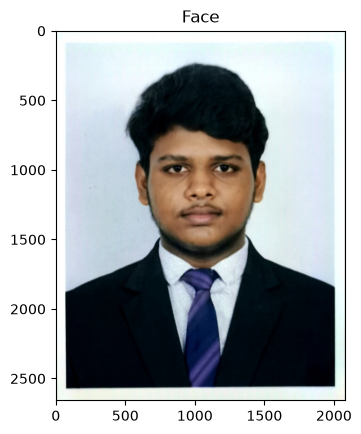

In [2]:
# Load the Face Image
faceImage = cv2.imread(r"C:\Users\admin\Downloads\yogeshimg.jpg")
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [3]:
faceImage.shape

(2658, 2082, 3)

In [4]:
#resized_faceImage.shape
faceImage.shape

(2658, 2082, 3)

Text(0.5, 1.0, 'glassPNG')

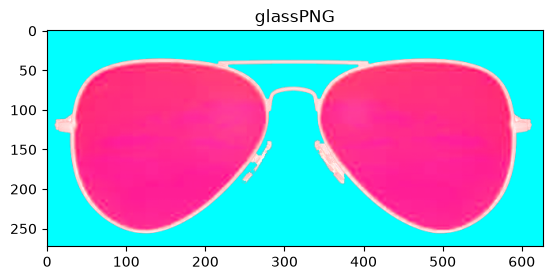

In [6]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread(r"C:\Users\admin\Downloads\sunglass-png-aviator-sunglass-png-pic-627.png",-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [7]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG,(190,50))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(50, 190, 4)


In [8]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:,:,0:3]
glassMask1 = glassPNG[:,:,3]

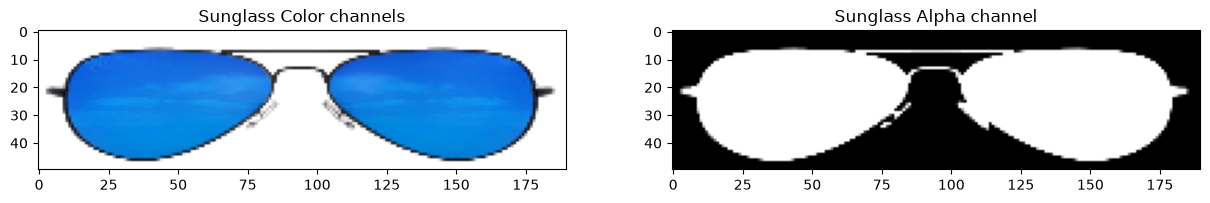

In [9]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

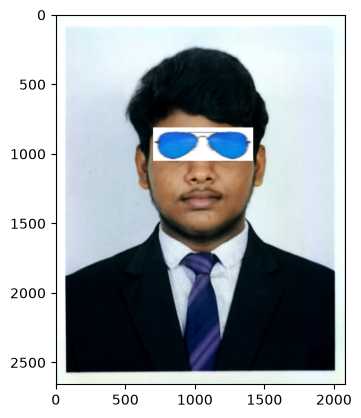

In [47]:
glassBGR = cv2.resize(glassBGR, (720, 240))

faceWithGlassesNaive = faceImage.copy()

faceWithGlassesNaive[810:1050, 700:1420] = glassBGR

plt.imshow(faceWithGlassesNaive[..., ::-1])

Text(0.5, 1.0, 'Augmented Eye and Sunglass')

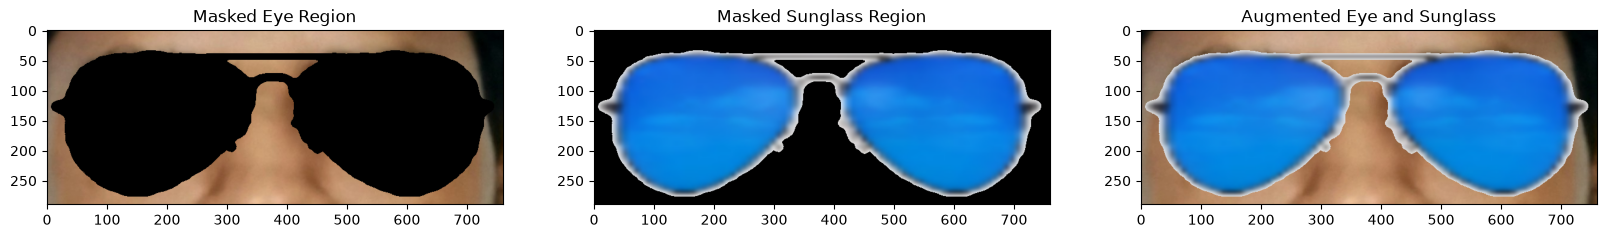

In [52]:
# Make the dimensions of the mask same as the input image
glassBGR = cv2.resize(glassBGR, (760, 290))

gray = cv2.cvtColor(glassBGR, cv2.COLOR_BGR2GRAY)
_, glassMask1 = cv2.threshold(gray, 220, 255, cv2.THRESH_BINARY_INV)

glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))

# Make the values [0,1]
glassMask = np.uint8(glassMask / 255)

# Make a copy
faceWithGlassesArithmetic = faceImage.copy()

# Shifted down to cover the eyes completely (Height: 290, Width: 760)
eyeROI = faceWithGlassesArithmetic[860:1150, 680:1440]

# Use the mask to create the masked eye region
maskedEye = cv2.multiply(eyeROI, (1 - glassMask))

# Use the mask to create the masked sunglass region
maskedGlass = cv2.multiply(glassBGR, glassMask)

# Combine the Sunglass in the Eye Region
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Display the intermediate results
plt.figure(figsize=[20, 20])
plt.subplot(131); plt.imshow(maskedEye[..., ::-1]); plt.title("Masked Eye Region")
plt.subplot(132); plt.imshow(maskedGlass[..., ::-1]); plt.title("Masked Sunglass Region")
plt.subplot(133); plt.imshow(eyeRoiFinal[..., ::-1]); plt.title("Augmented Eye and Sunglass")

Text(0.5, 1.0, 'With Sunglasses')

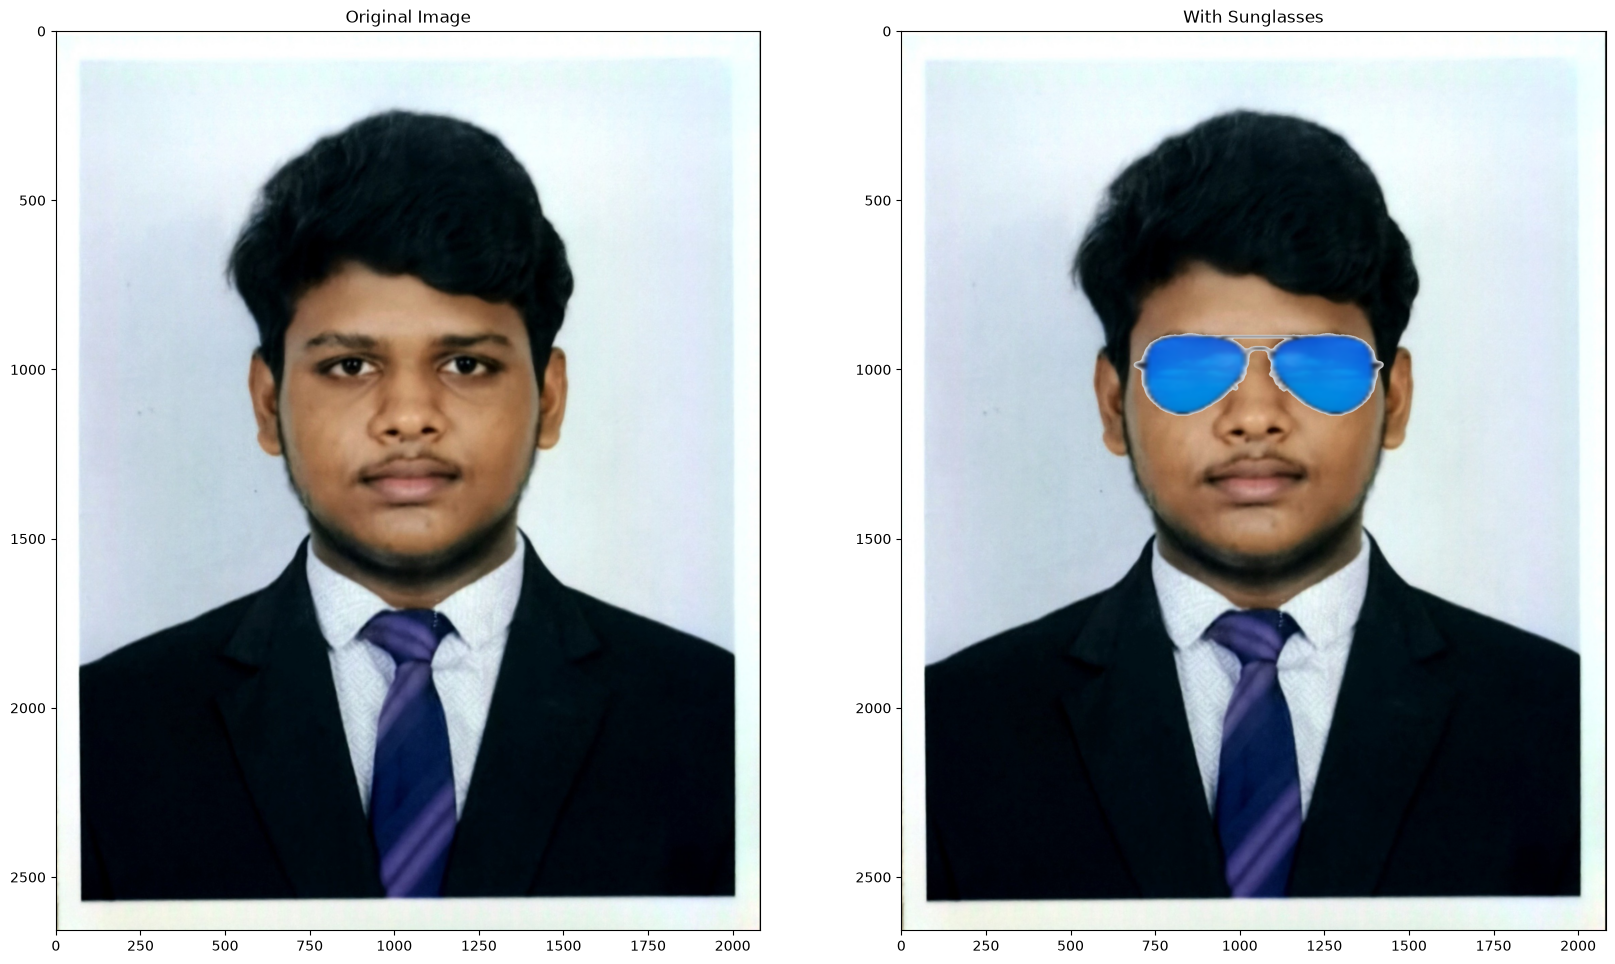

In [54]:
# Replace the eye ROI with the output from the previous section
faceWithGlassesArithmetic[860:1150, 680:1440] = eyeRoiFinal

# Display the final result
plt.figure(figsize=[20, 20])
plt.subplot(121); plt.imshow(faceImage[:, :, ::-1]); plt.title("Original Image")
plt.subplot(122); plt.imshow(faceWithGlassesArithmetic[:, :, ::-1]); plt.title("With Sunglasses")